# ❤️ Heart Disease Risk Prediction: Model Training and Evaluation

This notebook trains and compares two models that predict whether a patient has heart disease,
then saves the final model used by the Streamlit app (`ui.py`).

**Steps**
1. Import libraries
2. Load the cleaned data
3. Split into training and test sets
4. Train and evaluate two models
5. Confusion matrices
6. Choose and save the final model

**Data:** `heart_disease_ml_ready.csv` is the cleaned UCI Heart Disease dataset
(duplicates removed, missing values filled, outliers capped, text columns one-hot encoded).
The target column `heart_disease` is `1` when the patient has heart disease and `0` otherwise.

## 1. Import libraries

In [1]:
# Data handling and plotting
import pandas as pd
import matplotlib.pyplot as plt

# Models, data splitting and evaluation
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
                             confusion_matrix, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Saving the final model
import joblib

## 2. Load the cleaned data

In [2]:
# Read the cleaned dataset (keep the CSV in the same folder as this notebook)
df = pd.read_csv("heart_disease_ml_ready.csv")

# Quick look at the size of the data and how balanced the target is
print("Shape (rows, columns):", df.shape)
print("\nTarget counts (0 = no disease, 1 = disease):")
print(df["heart_disease"].value_counts())

# First five rows
df.head()

Shape (rows, columns): (916, 20)

Target counts (0 = no disease, 1 = disease):
heart_disease
1    506
0    410
Name: count, dtype: int64


,age,is_male,cholesterol,max_heart_rate,exercise_angina,st_depression,num_major_vessels,chest_pain_type_asymptomatic,chest_pain_type_atypical_angina,chest_pain_type_non_anginal,chest_pain_type_typical_angina,st_slope_downsloping,st_slope_flat,st_slope_missing,st_slope_upsloping,thalassemia_fixed_defect,thalassemia_missing,thalassemia_normal,thalassemia_reversible_defect,heart_disease
0,63,1,233.0,150.0,0,2.3,0,0,0,0,1,1,0,0,0,1,0,0,0,0
1,67,1,286.0,108.0,1,1.5,3,1,0,0,0,0,1,0,0,0,0,1,0,1
2,67,1,229.0,129.0,1,2.6,2,1,0,0,0,0,1,0,0,0,0,0,1,1
3,37,1,250.0,187.0,0,3.5,0,0,0,1,0,1,0,0,0,0,0,1,0,0
4,41,0,204.0,172.0,0,1.4,0,0,1,0,0,0,0,0,1,0,0,1,0,0


## 3. Split into training and test sets

- `X` holds the input columns and `y` holds the value we want to predict.
- 80% of the patients are used for training and 20% for testing.
- `stratify=y` keeps the disease / no-disease ratio the same in both parts.
- `random_state=42` makes the split repeatable.

In [3]:
# Inputs (X) and target (y)
X = df.drop(columns="heart_disease")
y = df["heart_disease"]

# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training patients:", len(X_train), "| Test patients:", len(X_test))

Training patients: 732 | Test patients: 184


## 4. Train and evaluate two models

- **Logistic Regression** is simple and easy to explain. It needs scaled inputs, so scaling is
  bundled with the model in a pipeline.
- **Random Forest** combines many decision trees and can find more complex patterns.

Each model is scored on the test set that it has never seen:
- **ROC-AUC:** how well the model separates sick from healthy patients (0.5 = guessing, 1.0 = perfect)
- **Precision:** of the patients flagged as sick, how many really are
- **Recall:** of the patients who really are sick, how many the model catches

In [4]:
# The two models to compare
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)                    # learn from the training data
    proba = model.predict_proba(X_test)[:, 1]      # probability of disease for each test patient

    print(f"\n{name}  |  Test AUC: {roc_auc_score(y_test, proba):.3f}")
    print(classification_report(y_test, model.predict(X_test)))


Logistic Regression  |  Test AUC: 0.903
              precision    recall  f1-score   support

           0       0.82      0.73      0.77        82
           1       0.80      0.87      0.84       102

    accuracy                           0.81       184
   macro avg       0.81      0.80      0.80       184
weighted avg       0.81      0.81      0.81       184


Random Forest  |  Test AUC: 0.913
              precision    recall  f1-score   support

           0       0.82      0.76      0.78        82
           1       0.81      0.86      0.84       102

    accuracy                           0.82       184
   macro avg       0.82      0.81      0.81       184
weighted avg       0.82      0.82      0.81       184



## 5. Confusion matrices

Rows show the **actual** class and columns show the **predicted** class.
The bottom-left box counts sick patients the model **missed** (false negatives). In a medical
problem this is the most costly mistake, so it should be as small as possible.

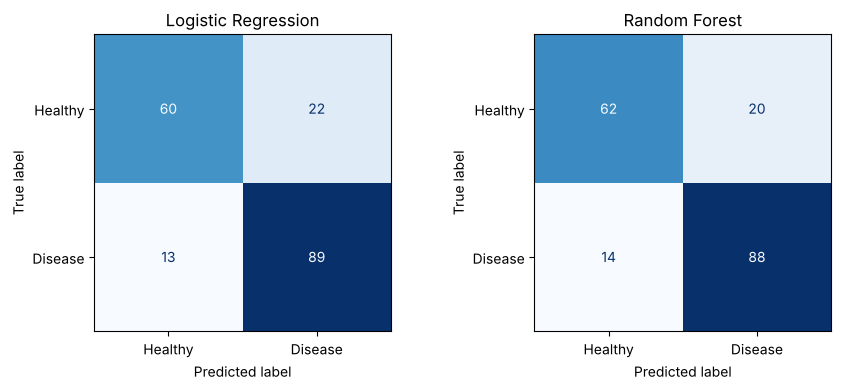

In [5]:
# One confusion matrix per model, side by side
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["Healthy", "Disease"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 6. Choose and save the final model

Both models perform very similarly (ROC-AUC 0.903 vs 0.913). **Logistic Regression** is chosen
because its recall for disease is slightly higher, it is easy to explain, and it works well on
this small dataset.

The saved file contains the scaler and the model together, so the Streamlit app can use it directly.

In [6]:
# Save the final model (scaler + Logistic Regression).
# Note: running this cell again overwrites heart_model.pkl.
final_model = models["Logistic Regression"]
joblib.dump(final_model, "heart_model.pkl")

# Check: reload the saved file and confirm it gives the same test score
reloaded = joblib.load("heart_model.pkl")
reloaded_auc = roc_auc_score(y_test, reloaded.predict_proba(X_test)[:, 1])
print("Saved model test AUC:", round(reloaded_auc, 3))

Saved model test AUC: 0.903


## Next step

Run the web app from a terminal in this folder:

```bash
streamlit run ui.py
```